# Euro-Area Yield-Curve Reconstruction: Baseline Checkpoint

This notebook runs the complete data and evaluation pipeline for the course baseline. It reconstructs five ECB AAA euro-area spot-rate changes from observed changes at 2Y, 10Y, and 30Y using multi-output Ridge regression.

The design is chronological: model selection uses only training data, evaluation uses a later validation period, and observations from 2022 onward remain untouched for the final project.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
DATA_PATH = ROOT / 'data' / 'raw' / 'ecb_yield_curve.csv'
RESULTS_DIR = ROOT / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MATURITIES = ['3M', '6M', '1Y', '2Y', '5Y', '10Y', '20Y', '30Y']
INPUTS = ['2Y', '10Y', '30Y']
TARGETS = ['3M', '6M', '1Y', '5Y', '20Y']
TRAIN_END = '2016-12-31'
VALIDATION_END = '2021-12-31'
SEED = 4020
BLOCK_LENGTH = 20
BOOTSTRAP_REPLICATES = 2000
ALPHAS = np.logspace(-5, 4, 40)

GROUP_NAME = '[]'
REPO_URL = '[]'

## 1. Load and prepare the ECB data

The downloaded file contains eight spot-rate levels in percent per annum. We align the dates, require all eight maturities, and convert first differences to basis points. The only mechanically dropped row should be the first date, which has no prior observation.

In [6]:
DATA_PATH = "/Users/libra/Desktop/ecb_yield_curve.csv"

In [9]:
def maturity_from_column(column):
    match = re.search(r'\.SR_(3M|6M|1Y|2Y|5Y|10Y|20Y|30Y)\)', column)
    return match.group(1) if match else None

raw = pd.read_csv(DATA_PATH)
date_column = 'DATE' if 'DATE' in raw.columns else 'TIME PERIOD'
rename = {column: maturity_from_column(column) for column in raw.columns}
rename = {column: label for column, label in rename.items() if label is not None}
assert sorted(rename.values()) == sorted(MATURITIES), f'Unexpected maturities: {sorted(rename.values())}'

levels = raw[[date_column, *rename.keys()]].rename(columns=rename)
levels[date_column] = pd.to_datetime(levels[date_column], errors='raise')
levels = levels.set_index(date_column)[MATURITIES].sort_index()
assert not levels.index.duplicated().any(), 'Duplicate dates found'
levels = levels.apply(pd.to_numeric, errors='coerce')
missing_rows = int(levels.isna().any(axis=1).sum())
complete_levels = levels.dropna()
changes = complete_levels.diff().mul(100).dropna()

data_summary = pd.Series({
    'raw level rows': len(raw),
    'rows with a missing maturity': missing_rows,
    'complete daily changes': len(changes),
    'first change date': changes.index.min().date(),
    'last change date': changes.index.max().date(),
    'number of inputs': len(INPUTS),
    'number of outputs': len(TARGETS),
})
display(data_summary.to_frame('value'))

,value
raw level rows,5669
rows with a missing maturity,0
complete daily changes,5668
first change date,2004-09-07
last change date,2026-11-06
number of inputs,3
number of outputs,5


## 2. Chronological split

The validation period is not used for scaling, fitting, or selecting the Ridge penalty. The final test period stays untouched in this notebook.

In [10]:
train = changes.loc[:TRAIN_END]
validation = changes.loc[pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1):VALIDATION_END]
test = changes.loc[pd.Timestamp(VALIDATION_END) + pd.Timedelta(days=1):]

split_summary = pd.DataFrame({
    'period': ['Training', 'Validation', 'Locked final test'],
    'start': [train.index.min().date(), validation.index.min().date(), test.index.min().date()],
    'end': [train.index.max().date(), validation.index.max().date(), test.index.max().date()],
    'N': [len(train), len(validation), len(test)],
})
display(split_summary)

,period,start,end,N
0,Training,2004-09-07,2016-12-30,3155
1,Validation,2017-01-02,2021-12-31,1273
2,Locked final test,2022-01-03,2026-11-06,1240


## 3. Tune the Ridge baseline inside the training period

Standardization is inside the pipeline, so each cross-validation fold estimates its scaling parameters using only that fold's training observations. `TimeSeriesSplit` creates five expanding, time-ordered folds without shuffling.

In [11]:
pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('ridge', Ridge()),
])

search = GridSearchCV(
    pipeline,
    {'ridge__alpha': ALPHAS},
    scoring='neg_root_mean_squared_error',
    cv=TimeSeriesSplit(n_splits=5),
    n_jobs=-1,
    return_train_score=False,
)
search.fit(train[INPUTS], train[TARGETS])
predicted = search.predict(validation[INPUTS])
pd.DataFrame(search.cv_results_).to_csv(RESULTS_DIR / 'ridge_cv_results.csv', index=False)
print(f"Selected alpha: {search.best_params_['ridge__alpha']:.6g}")

Selected alpha: 28.9427


## 4. Score unseen validation data with a moving-block bootstrap

Daily rate volatility clusters, so resampling individual days would understate dependence. We resample consecutive 20-business-day blocks and report percentile intervals from 2,000 replicates. The seed affects only the bootstrap.

In [15]:
def rmse(actual, forecast, axis=None):
    return np.sqrt(np.mean((actual - forecast) ** 2, axis=axis))

def moving_block_indices(n, block_length, rng):
    block_count = int(np.ceil(n / block_length))
    starts = rng.integers(0, n - block_length + 1, size=block_count)
    return np.concatenate([np.arange(start, start + block_length) for start in starts])[:n]

actual = validation[TARGETS].to_numpy()
rng = np.random.default_rng(SEED)
bootstrap_samples = np.empty((BOOTSTRAP_REPLICATES, len(TARGETS) + 1))
for b in range(BOOTSTRAP_REPLICATES):
    idx = moving_block_indices(len(validation), BLOCK_LENGTH, rng)
    errors = actual[idx] - predicted[idx]
    bootstrap_samples[b, :-1] = np.sqrt(np.mean(errors ** 2, axis=0))
    bootstrap_samples[b, -1] = np.sqrt(np.mean(errors ** 2))

point = np.r_[rmse(actual, predicted, axis=0), rmse(actual, predicted)]
lower = np.quantile(bootstrap_samples, 0.025, axis=0)
upper = np.quantile(bootstrap_samples, 0.975, axis=0)
labels = TARGETS + ['Overall']
metrics = pd.DataFrame({
    'target': labels,
    'rmse_bps': point,
    'ci_2.5%': lower,
    'ci_97.5%': upper,
})
metrics.to_csv(RESULTS_DIR / 'baseline_metrics.csv', index=False)
display(metrics.round(3))

,target,rmse_bps,ci_2.5%,ci_97.5%
0,3M,1.593,1.312,1.772
1,6M,1.213,1.005,1.353
2,1Y,0.657,0.551,0.734
3,5Y,0.530,0.470,0.590
4,20Y,0.404,0.345,0.465
5,Overall,0.988,0.831,1.096


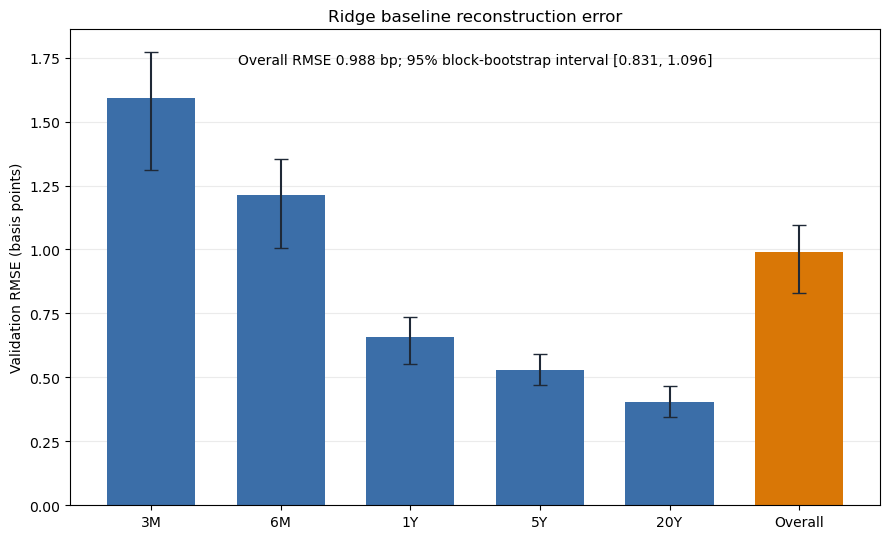

In [16]:
figure, axis = plt.subplots(figsize=(9, 5.5))
positions = np.arange(len(labels))
errors = np.vstack([point - lower, upper - point])
colors = ['#3B6EA8'] * len(TARGETS) + ['#D97706']
axis.bar(positions, point, color=colors, width=0.68)
axis.errorbar(positions, point, yerr=errors, fmt='none', ecolor='#1F2937', capsize=5, linewidth=1.5)
axis.set_xticks(positions, labels)
axis.set_ylabel('Validation RMSE (basis points)')
axis.set_title('Ridge baseline reconstruction error')
axis.text(
    0.5, 0.95,
    f'Overall RMSE {point[-1]:.3f} bp; 95% block-bootstrap interval [{lower[-1]:.3f}, {upper[-1]:.3f}]',
    ha='center', va='top', transform=axis.transAxes, fontsize=10,
)
axis.grid(axis='y', alpha=0.25)
axis.set_axisbelow(True)
figure.tight_layout()
figure.savefig(RESULTS_DIR / 'baseline.png', dpi=200)
plt.show()